<a href="https://colab.research.google.com/github/Paatogodui1/ATM_Machine/blob/main/Sars.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.4/36.4 MB 18.9 MB/s eta 0:00:00


In [ ]:
pip install torch

In [ ]:
drive.mount('/content/drive')
work_dir = "/content/drive/MyDrive/Bioinformatics model/"
os.chdir(work_dir)
print("Current working directory:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Current working directory: /content/drive/MyDrive/Bioinformatics model


In [ ]:
active = "active.csv"
act = pd.read_csv(active)
act

,PUBCHEM_SID,PUBCHEM_EXT_DATASOURCE_SMILES
0,NaN,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,103958950.0,C1=CC=C(C=C1)NC2=NC3=CC=CC=C3C(=O)O2
...,...,...
923,485209121.0,C1CCN(C1)CCOC2=CC3=C(C=NC=C3C=C2)N4CCC5(C4=O)C...
924,485209122.0,CCN(C)CCOC1=CC2=C(C=NC=C2C=C1)N3CCC4(C3=O)CN(C...
925,485209123.0,CCN(CC)CCOC1=CC2=C(C=NC=C2C=C1)N3CCC4(C3=O)CN(...
926,485209124.0,C1CC1(CS(=O)(=O)N2CC3=C(C=C(C=C3)Cl)C4(C2)CCN(...


In [ ]:
  import os
  import pandas as pd
  import numpy as np
  import seaborn as sns
  import re
  from rdkit import Chem
  from rdkit.Chem import AllChem, Descriptors, Draw
  import torch
  from tqdm import tqdm
  import subprocess
  from tkinter import filedialog as fd
  import joblib
  from sklearn.metrics import confusion_matrix, accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, auc, roc_curve, matthews_corrcoef
  from sklearn.impute import SimpleImputer
  from sklearn.feature_selection import VarianceThreshold
  from sklearn.model_selection import KFold, cross_val_score, cross_val_predict, train_test_split, StratifiedKFold
  from sklearn.neighbors import KNeighborsClassifier
  from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
  from sklearn.naive_bayes import GaussianNB
  from sklearn.svm import SVC
  from sklearn.linear_model import LogisticRegression
  import matplotlib.pyplot as plt
  from google.colab import drive
  import warnings
  from xgboost import XGBClassifier

In [ ]:
inactive = "inactive (1).csv"
inact = pd.read_csv(inactive)
inact

,PUBCHEM_SID,PUBCHEM_EXT_DATASOURCE_SMILES
0,NaN,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,49847024.0,C[C@@H]1CC[C@@]2(CC[C@@]3(C(=CC[C@H]4[C@]3(CC[...
...,...,...
1008,485209090.0,C1CC1N2C=NN=C2NC(=O)C3CN(CC4=C3C=C(C=C4)Cl)S(=...
1009,485209091.0,C1CC1(CS(=O)(=O)N2CC3=C(C=C(C=C3)Cl)C4(C2)CCN(...
1010,485209094.0,CNC(=O)CN1CC2=C(C=C(C=C2)Cl)[C@@]3(C1)CCN(C3=O...
1011,485209096.0,CNC(=O)CN1C[C@]2(CCN(C2=O)C3=CN=CC4=CC=CC=C43)...


In [ ]:
smiles_list_active = act['PUBCHEM_EXT_DATASOURCE_SMILES'].dropna().tolist()
mols_active = [Chem.MolFromSmiles(smi) for smi in smiles_list_active]

In [ ]:
def morgan_fps(data):
    fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in data]
    fp_array = [np.array(fp) for fp in fps]
    column_names = ["morgan_" + str(i) for i in range(2048)]
    return pd.DataFrame(fp_array, columns=column_names)

X = morgan_fps(mols_active)
X

[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerator
[10:33:20] DEPRECATION WARNING: please use MorganGenerat

,morgan_0,morgan_1,morgan_2,morgan_3,morgan_4,morgan_5,morgan_6,morgan_7,morgan_8,morgan_9,...,morgan_2038,morgan_2039,morgan_2040,morgan_2041,morgan_2042,morgan_2043,morgan_2044,morgan_2045,morgan_2046,morgan_2047
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
919,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
920,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
921,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
922,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
smiles_list_inactive = inact['PUBCHEM_EXT_DATASOURCE_SMILES'].dropna().tolist()
mols_inactive = [Chem.MolFromSmiles(smi) for smi in smiles_list_inactive]

In [ ]:
def morgan_fps(data):
    fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in data]
    fp_array = [np.array(fp) for fp in fps]
    column_names = ["morgan_" + str(i) for i in range(2048)]
    return pd.DataFrame(fp_array, columns=column_names)

Y = morgan_fps(mols_inactive)
Y

[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerator
[11:26:04] DEPRECATION WARNING: please use MorganGenerat

,morgan_0,morgan_1,morgan_2,morgan_3,morgan_4,morgan_5,morgan_6,morgan_7,morgan_8,morgan_9,...,morgan_2038,morgan_2039,morgan_2040,morgan_2041,morgan_2042,morgan_2043,morgan_2044,morgan_2045,morgan_2046,morgan_2047
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1004,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1005,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1006,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1007,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
m=np.ones((X.shape[0],1))
n=np.zeros((Y.shape[0],1))
labels = np.concatenate((m,n,),axis=0)
labels

array([[1.],
       [1.],
       [1.],
       ...,
       [0.],
       [0.],
       [0.]])

In [ ]:
#Reading descriptor data into memory
combined_data = pd.concat([X,Y],axis=0)
combined_data['Labels'] = labels
Data = combined_data.iloc[:,1:]
Data.to_csv('combined_data.csv',index=False)
Data

,morgan_1,morgan_2,morgan_3,morgan_4,morgan_5,morgan_6,morgan_7,morgan_8,morgan_9,morgan_10,...,morgan_2039,morgan_2040,morgan_2041,morgan_2042,morgan_2043,morgan_2044,morgan_2045,morgan_2046,morgan_2047,Labels
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1004,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0.0
1005,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0.0
1006,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0.0
1007,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0.0


In [ ]:
duplicates = Data[Data.duplicated(keep=False)]
print(duplicates)

     morgan_1  morgan_2  morgan_3  morgan_4  morgan_5  morgan_6  morgan_7  \
16          0         0         0         0         0         0         0   
17          0         0         0         0         0         0         0   
25          0         0         0         0         0         0         0   
31          1         0         0         0         0         0         0   
32          1         0         0         0         0         0         0   
..        ...       ...       ...       ...       ...       ...       ...   
474         0         0         0         0         0         0         0   
793         1         0         0         0         0         0         0   
794         1         0         0         0         0         0         0   
795         1         0         0         0         0         0         0   
805         1         0         0         0         0         0         0   

     morgan_8  morgan_9  morgan_10  ...  morgan_2039  morgan_2040  \
16    

In [ ]:
unique_data = Data.drop_duplicates(subset=Data.columns.difference(['Labels']))
unique_data.to_csv('unique_data.csv', index=False)
unique_data

,morgan_1,morgan_2,morgan_3,morgan_4,morgan_5,morgan_6,morgan_7,morgan_8,morgan_9,morgan_10,...,morgan_2039,morgan_2040,morgan_2041,morgan_2042,morgan_2043,morgan_2044,morgan_2045,morgan_2046,morgan_2047,Labels
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1001,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0.0
1002,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0.0
1003,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0.0
1004,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0.0


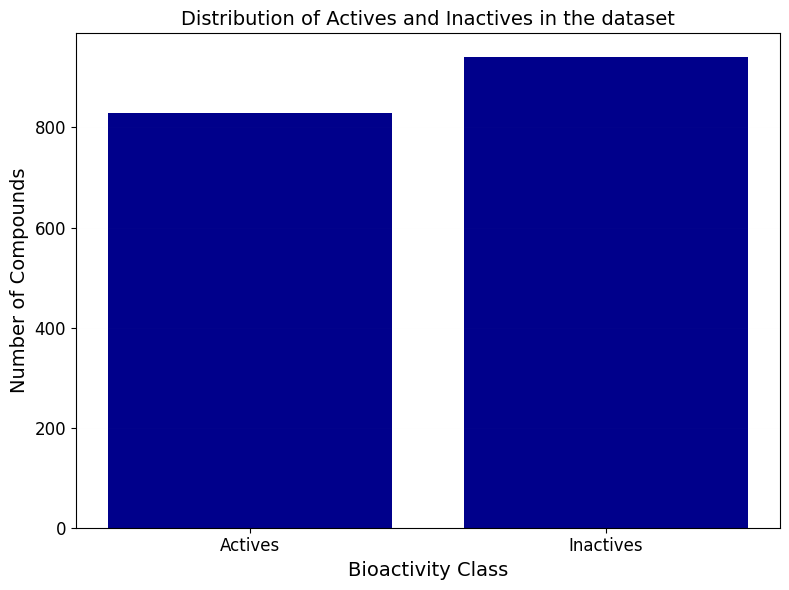

In [ ]:
actives = (unique_data['Labels'] == 1).sum()
inactives = (unique_data['Labels'] == 0).sum()

# Data for the bar chart
categories = ['Actives', 'Inactives']
counts = [actives, inactives]

# Create the bar chart
plt.figure(figsize=(8, 6))
plt.bar(categories, counts, color= '#00008B')
plt.title('Distribution of Actives and Inactives in the dataset', fontsize=14)
plt.xlabel('Bioactivity Class', fontsize=14)
plt.ylabel('Number of Compounds', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', alpha=0.01)

plt.tight_layout()
plt.show()

In [ ]:
labels = list(unique_data['Labels'])
Data=unique_data.iloc[:,:-1]
Data

,morgan_1,morgan_2,morgan_3,morgan_4,morgan_5,morgan_6,morgan_7,morgan_8,morgan_9,morgan_10,...,morgan_2038,morgan_2039,morgan_2040,morgan_2041,morgan_2042,morgan_2043,morgan_2044,morgan_2045,morgan_2046,morgan_2047
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1001,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1002,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1003,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1004,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [ ]:
Data = Data.fillna(0)
def rem_var(input_data, threshold=0.1):
    sel = VarianceThreshold(threshold)
    sel.fit(input_data)
    return input_data[input_data.columns[sel.get_support(indices=True)]]

Data = rem_var(Data, threshold=0.1)
Data

,morgan_1,morgan_33,morgan_41,morgan_63,morgan_80,morgan_104,morgan_114,morgan_142,morgan_165,morgan_186,...,morgan_1816,morgan_1855,morgan_1866,morgan_1905,morgan_1908,morgan_1928,morgan_1946,morgan_1948,morgan_1980,morgan_1985
0,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,1,0,0,0,...,0,1,0,0,0,1,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1001,1,1,0,0,1,1,0,0,0,1,...,0,0,1,0,0,1,0,0,0,1
1002,1,1,0,0,1,1,0,0,0,1,...,1,0,1,0,0,1,0,0,0,1
1003,1,1,0,0,1,1,0,0,0,1,...,0,0,1,0,0,1,0,0,0,1
1004,0,0,0,0,1,0,0,0,1,0,...,1,0,0,0,0,0,1,0,1,0


In [ ]:
col = Data.columns
metrics=['mean','std']
dp = pd.DataFrame(metrics,columns=['metrics'])
for i in col:
    array = np.array(Data[i])
    mean = Data[i].mean()
    std = Data[i].std()
    c = [mean,std]
    dp[i]=c
dp.to_csv('metrics.csv',index=False)
dp

/tmp/ipython-input-4154599560.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dp[i]=c
/tmp/ipython-input-4154599560.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dp[i]=c
/tmp/ipython-input-4154599560.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dp[i]=c
/tmp/ipython-input-4154599560.p

,metrics,morgan_1,morgan_33,morgan_41,morgan_63,morgan_80,morgan_104,morgan_114,morgan_142,morgan_165,...,morgan_1816,morgan_1855,morgan_1866,morgan_1905,morgan_1908,morgan_1928,morgan_1946,morgan_1948,morgan_1980,morgan_1985
0,mean,0.284341,0.187111,0.272470,0.391181,0.741662,0.152063,0.167326,0.424534,0.439796,...,0.495760,0.461843,0.314302,0.122103,0.319955,0.251555,0.127191,0.141888,0.212549,0.159412
1,std,0.451228,0.390111,0.445356,0.488153,0.437845,0.359184,0.373372,0.494412,0.496503,...,0.500123,0.498683,0.464368,0.327497,0.466591,0.434029,0.333280,0.349034,0.409227,0.366163


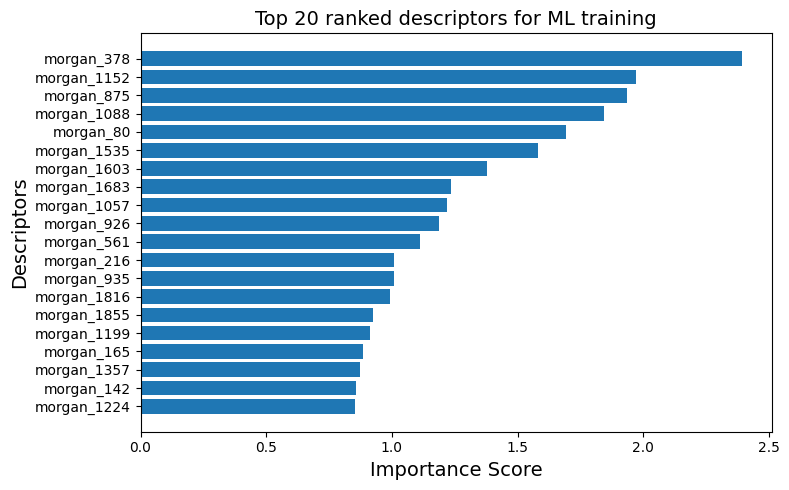

In [ ]:
df = pd.read_csv("metrics.csv", index_col=0)

df = df.T
df.columns = ['mean', 'std']

df['importance_score'] = abs(df['mean']) / df['std']
df_sorted = df.sort_values(by='importance_score', ascending=False)
top_20 = df_sorted.head(20)

# Plot
plt.figure(figsize=(8, 5))
plt.barh(top_20.index[::-1], top_20['importance_score'][::-1])
plt.title("Top 20 ranked descriptors for ML training", fontsize=14)
plt.xlabel("Importance Score", fontsize=14)
plt.ylabel("Descriptors", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
df = pd.DataFrame()
for i in col:
    array = np.array(Data[i])
    mean = dp[i][0]
    std = dp[i][1]
    aa=[]
    for j in array:

        n = ((j-mean)/std)
        aa.append(n)

    df[i]=aa

df['Labels'] = labels
Data = df.sample(frac=1).reset_index(drop=True)

/tmp/ipython-input-4046411159.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[i]=aa
/tmp/ipython-input-4046411159.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[i]=aa
/tmp/ipython-input-4046411159.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[i]=aa
/tmp/ipython-input-404641

In [ ]:
Data

,morgan_1,morgan_33,morgan_41,morgan_63,morgan_80,morgan_104,morgan_114,morgan_142,morgan_165,morgan_186,...,morgan_1855,morgan_1866,morgan_1905,morgan_1908,morgan_1928,morgan_1946,morgan_1948,morgan_1980,morgan_1985,Labels
0,-0.630151,-0.479636,-0.611803,-0.801350,-1.693893,-0.423358,-0.448148,-0.858664,1.128299,-0.458113,...,-0.926125,1.476625,-0.372836,-0.685729,-0.579580,-0.381632,-0.406517,-0.519392,-0.435358,0.0
1,1.586025,-0.479636,1.633590,1.247188,0.590022,-0.423358,-0.448148,1.163941,1.128299,-0.458113,...,1.079157,-0.676837,-0.372836,1.457477,-0.579580,-0.381632,-0.406517,-0.519392,-0.435358,1.0
2,-0.630151,-0.479636,1.633590,-0.801350,0.590022,-0.423358,2.230143,1.163941,1.128299,-0.458113,...,1.079157,-0.676837,-0.372836,-0.685729,1.724413,2.618844,-0.406517,1.924238,-0.435358,1.0
3,-0.630151,-0.479636,-0.611803,-0.801350,-1.693893,-0.423358,-0.448148,-0.858664,-0.885789,-0.458113,...,-0.926125,-0.676837,-0.372836,-0.685729,-0.579580,-0.381632,-0.406517,-0.519392,-0.435358,0.0
4,1.586025,-0.479636,-0.611803,-0.801350,-1.693893,-0.423358,2.230143,-0.858664,-0.885789,-0.458113,...,-0.926125,-0.676837,-0.372836,-0.685729,1.724413,-0.381632,-0.406517,-0.519392,-0.435358,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1764,-0.630151,-0.479636,1.633590,-0.801350,0.590022,-0.423358,-0.448148,-0.858664,1.128299,-0.458113,...,-0.926125,-0.676837,-0.372836,-0.685729,-0.579580,-0.381632,2.458534,-0.519392,-0.435358,0.0
1765,1.586025,2.083736,-0.611803,-0.801350,0.590022,2.360732,2.230143,-0.858664,-0.885789,2.181633,...,1.079157,1.476625,-0.372836,-0.685729,1.724413,-0.381632,-0.406517,-0.519392,2.295663,0.0
1766,1.586025,-0.479636,1.633590,-0.801350,0.590022,-0.423358,-0.448148,-0.858664,-0.885789,-0.458113,...,-0.926125,-0.676837,-0.372836,-0.685729,1.724413,-0.381632,-0.406517,-0.519392,-0.435358,0.0
1767,-0.630151,-0.479636,-0.611803,1.247188,-1.693893,-0.423358,-0.448148,1.163941,-0.885789,-0.458113,...,1.079157,1.476625,-0.372836,1.457477,-0.579580,-0.381632,-0.406517,-0.519392,-0.435358,1.0


In [ ]:
act = 0
inact = 0
for i in Data['Labels']:
    if int(i) == 1:
        act+=1
    else:
        inact+=1

print('Active Compounds: ', act)
print('Inactive Compounds: ', inact)

Active Compounds:  828
Inactive Compounds:  941


In [ ]:
train_df, test_df = train_test_split(Data, test_size=0.2, random_state=42)

print("Train DataFrame:")
print(len(train_df))

print("\nTest DataFrame:")
print(len(test_df))

Train DataFrame:
1415

Test DataFrame:
354


In [ ]:
test_df.to_csv('Test Data.csv',index=False)
train_df.to_csv('Training Data.csv',index=False)

Performing cross-validation on KNN...
Fitting KNN...
Successful!
Performing cross-validation on NB...
Fitting NB...
Successful!
Performing cross-validation on SVM...
Fitting SVM...
Successful!
Performing cross-validation on AdaBoost...
Fitting AdaBoost...
Successful!
Performing cross-validation on XGBoost...


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [11:35:14] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [11:35:14] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [11:35:14] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [11:35:14] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [11:35:14] WARNING: /w

Fitting XGBoost...
Successful!
Performing cross-validation on RF...


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [11:35:15] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fitting RF...
Successful!
Performing cross-validation on LR...
Fitting LR...
Successful!


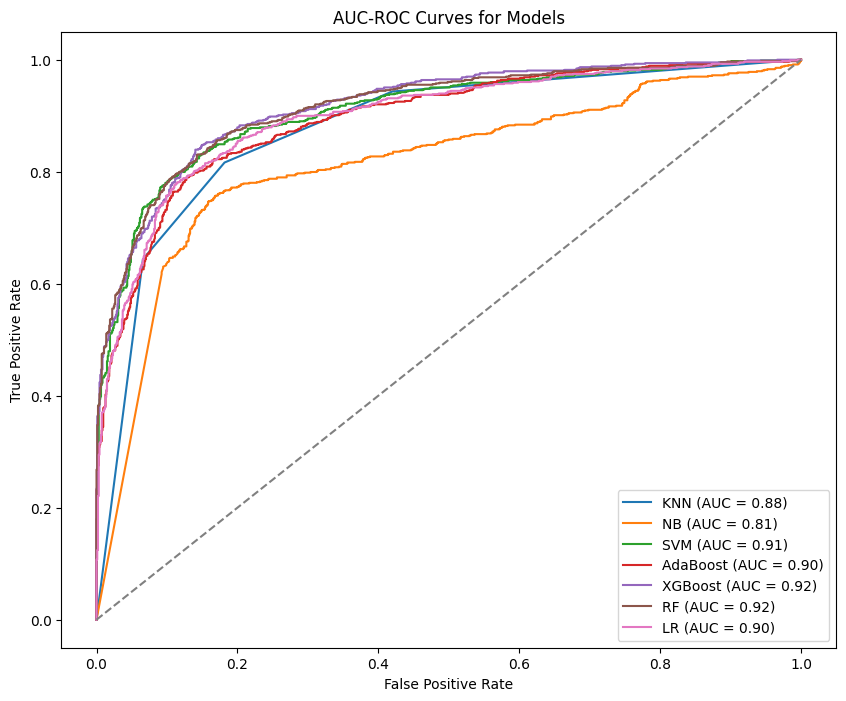

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,AUC Score
0,KNN,0.817411,0.817352,0.798111,0.816425,0.807164,0.878979
1,NB,0.791408,0.789937,0.782984,0.766908,0.774863,0.814319
2,SVM,0.840023,0.838171,0.842767,0.809179,0.825632,0.908521
3,AdaBoost,0.833239,0.830562,0.844761,0.788647,0.815740,0.895062
4,XGBoost,0.843414,0.841939,0.842236,0.818841,0.830374,0.917555
5,RF,0.843414,0.839691,0.870794,0.781401,0.823679,0.915438
6,LR,0.830413,0.828993,0.826733,0.806763,0.816626,0.898249


In [ ]:
models = [
    ('KNN', KNeighborsClassifier(n_neighbors=3)),
    ('NB', GaussianNB()),
    ('SVM', SVC(probability=True, random_state=42)),
    ('AdaBoost', AdaBoostClassifier(n_estimators=100, random_state=42)),
    ('XGBoost', XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)),
    ('RF', RandomForestClassifier(max_depth=8, n_estimators=100, random_state=42)),
    ('LR', LogisticRegression(max_iter=1000, random_state=42))
]

# Features and labels
X = Data.iloc[:, :-1]
y = Data.iloc[:, -1]

kfold = KFold(n_splits=10, shuffle=True, random_state=42)

results = []
conf_matrices = []
saved_models = {}

plt.figure(figsize=(10, 8))

for name, model in models:
    print(f'Performing cross-validation on {name}...')

    # Predict probabilities and class labels
    y_pred_proba = cross_val_predict(model, X, y, cv=kfold, method='predict_proba')
    y_pred = (y_pred_proba[:, 1] >= 0.5).astype(int)

    # Confusion matrix
    cm = confusion_matrix(y, y_pred)
    conf_matrices.append(cm)

    # Metrics using built-in functions
    accuracy = accuracy_score(y, y_pred)
    balanced_acc = balanced_accuracy_score(y, y_pred)
    precision = precision_score(y, y_pred, zero_division=0)
    recall = recall_score(y, y_pred, zero_division=0)
    f1 = f1_score(y, y_pred, zero_division=0)

    # ROC & AUC
    fpr, tpr, _ = roc_curve(y, y_pred_proba[:, 1])
    roc_auc = auc(fpr, tpr)

    # Store metrics
    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Balanced Accuracy': balanced_acc,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'AUC Score': roc_auc
    })

    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')

    # Final training
    print(f'Fitting {name}...')
    model.fit(X, y)
    saved_models[name] = model
    print('Successful!')

# Plot ROC curves
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('AUC-ROC Curves for Models')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# Save models
for name, model in saved_models.items():
    joblib.dump(model, f'{name}_model.pkl')

# Display results
results_df = pd.DataFrame(results)
results_df

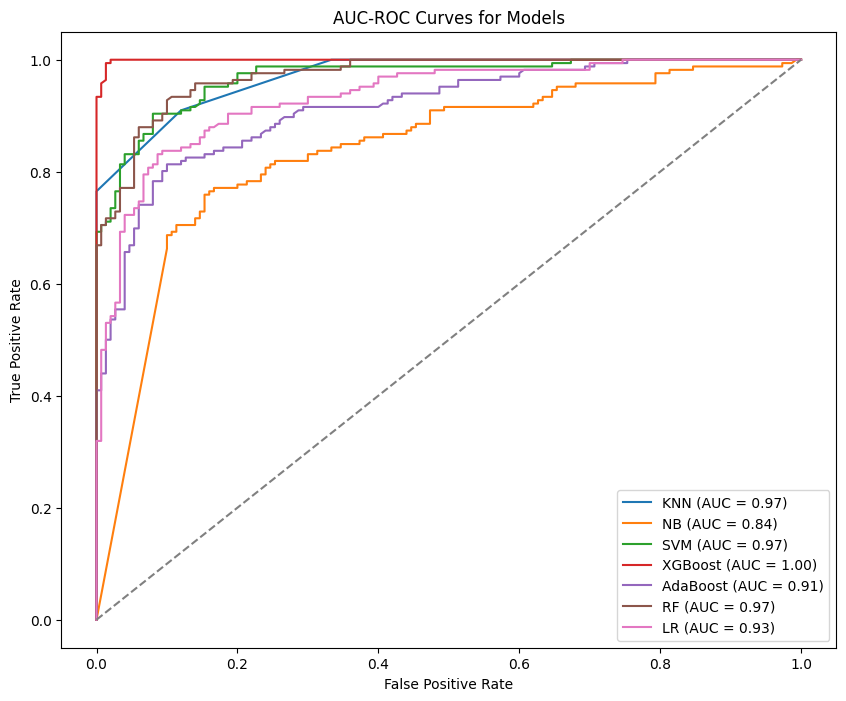

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,AUC Score
0,KNN,0.895570,0.894819,0.893491,0.909639,0.901493,0.970843
1,NB,0.797468,0.798876,0.831169,0.771084,0.800000,0.838855
2,SVM,0.895570,0.897711,0.940397,0.855422,0.895899,0.968695
3,XGBoost,0.987342,0.986988,0.982143,0.993976,0.988024,0.999257
4,AdaBoost,0.848101,0.849960,0.888158,0.813253,0.849057,0.914478
5,RF,0.889241,0.892008,0.945578,0.837349,0.888179,0.971707
6,LR,0.867089,0.868996,0.907895,0.831325,0.867925,0.933474


In [ ]:
# Load each model from .pkl files
model_names = ['KNN', 'NB', 'SVM', 'XGBoost', 'AdaBoost', 'RF', 'LR']
loaded_models = {name: joblib.load(f'{name}_model.pkl') for name in model_names}

combined_df = pd.read_csv("Test Data.csv")

X_combined = combined_df.iloc[:, :-1]
y_combined = combined_df.iloc[:, -1]

evaluation_results = []

plt.figure(figsize=(10, 8))

for name, model in loaded_models.items():
    y_pred = model.predict(X_combined)
    y_pred_proba = model.predict_proba(X_combined)[:, 1]

    accuracy = accuracy_score(y_combined, y_pred)
    balanced_acc = balanced_accuracy_score(y_combined, y_pred)
    precision = precision_score(y_combined, y_pred, average='binary')
    recall = recall_score(y_combined, y_pred, average='binary')
    f1 = f1_score(y_combined, y_pred, average='binary')
    auc_score = roc_auc_score(y_combined, y_pred_proba)

    evaluation_results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Balanced Accuracy': balanced_acc,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'AUC Score': auc_score
    })

    fpr, tpr, _ = roc_curve(y_combined, y_pred_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.2f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.title('AUC-ROC Curves for Models')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')

plt.show()

results_df = pd.DataFrame(evaluation_results)
results_df

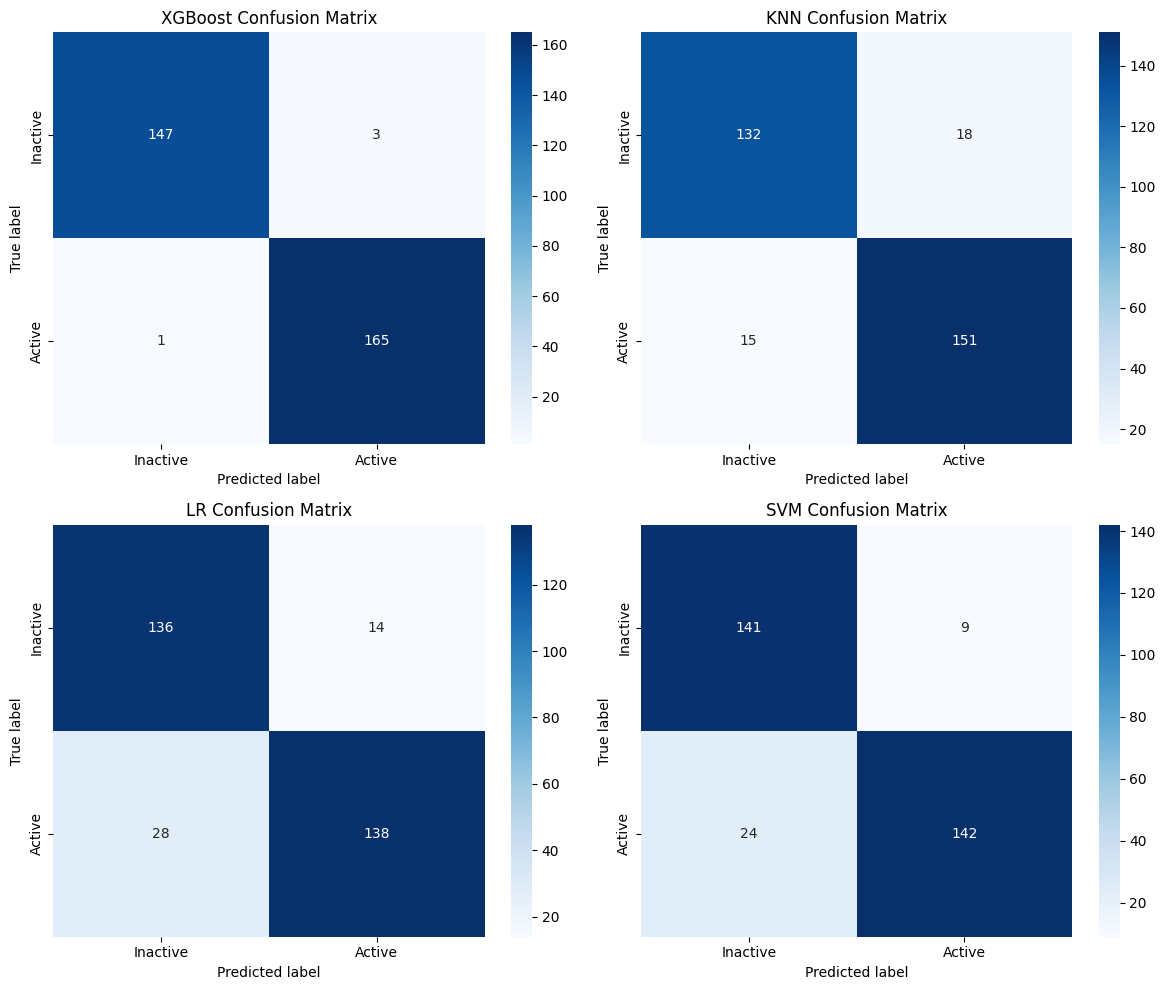

In [ ]:
# Load the models
XGBoost_model = joblib.load('XGBoost_model.pkl')
KNN_model = joblib.load('KNN_model.pkl')
LR_model = joblib.load('LR_model.pkl')
SVM_model = joblib.load('SVM_model.pkl')


test_df = pd.read_csv("Test Data.csv")

X_test = test_df.iloc[:, :-1]
y_test = test_df.iloc[:, -1]

models = {
   'XGBoost': XGBoost_model,
    'KNN': KNN_model,
    'LR': LR_model,
    'SVM': SVM_model
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    predictions = model.predict(X_test)
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=True)
    axes[i].set_title(f'{name} Confusion Matrix')
    axes[i].set_xlabel('Predicted label')
    axes[i].set_ylabel('True label')
    axes[i].set_xticklabels(['Inactive', 'Active'])
    axes[i].set_yticklabels(['Inactive', 'Active'])

plt.tight_layout()
plt.show()

# **PREDICTION OF KNOWN SARS INHIBITORS**

In [ ]:
dp = pd.read_csv('metrics.csv')
dp.drop('metrics',axis=1,inplace=True)

#Loading New SMILES with names
new_smiles = [
"CCC(CC)COC(=O)[C@H](C)N[P@](=O)(OC[C@H]1O[C@](C#N)([C@H](O)[C@@H]1O)C1=CC=C2N1N=CN=C2N)OC1=CC=CC=C1 remdesivir",
"OC(=O)C1=CC2=C(C(O)=C1)C(=O)C1=C(C=CC=C1O)C2=O rhein",
"CN1C=NC(CN2C(=O)NC(=NC3=CC4=CN(C)N=C4C=C3Cl)N(CC3=CC(F)=C(F)C=C3F)C2=O)=N1 Ensitrelvir",
"OC1=CC2=C(C(O)=C1)C(=O)C(O)=C(O2)C1=CC=C(O)C(O)=C1 quercetin",
"CC(C)[C@H](N1CCCNC1=O)C(=O)N[C@H](C[C@H](O)[C@H](CC1=CC=CC=C1)NC(=O)COC1=C(C)C=CC=C1C)CC1=CC=CC=C1 lopinavir",
"CC(C)[C@H](NC(=O)N(C)CC1=CSC(=N1)C(C)C)C(=O)N[C@H](C[C@H](O)[C@H](CC1=CC=CC=C1)NC(=O)OCC1=CN=CS1)CC1=CC=CC=C1 ritonavir",
"[H][C@@]12CCCC[C@]1([H])CN(C[C@@H](O)[C@H](CSC1=CC=CC=C1)NC(=O)C1=C(C)C(O)=CC=C1)[C@@H](C2)C(=O)NC(C)(C)C Nelfinavir mesylate",
"OC1=CC2=C(C(O)=C1O)C(=O)C=C(O2)C1=CC=CC=C1 Baicalein",
"OC1=CC=C(C=C1)C1=CC(=O)C2=C(O)C=C(O)C=C2O1 apigenin",
"O[C@@H]1[C@H](OC2=C(C(O)=CC(O)=C2)C1=O)C1=CC(O)=C(O)C(O)=C1 dihydromyricetin",
"C1CN2CC3=CC4=C(C=C3[C@H]5[C@H]2C1=C[C@@H]([C@H]5O)O)OCO4 Lycorine",
"COC(=O)N[C@H](C(=O)N[C@@H](CC1=CC=CC=C1)[C@@H](O)CN(CC1=CC=C(C=C1)C1=CC=CC=N1)NC(=O)[C@@H](NC(=O)OC)C(C)(C)C)C(C)(C)C Atazanavir",
"C[C@H]1CC[C@@H](CC1)C(=O)N([C@H]1CC[C@H](O)CC1)C1=C(SC(=C1)C#CC(C)(C)C)C(O)=O Lomibuvir",
"C[C@@H](C1=CC=CC=C1)NC(=O)[C@@H](C2=CN=CC=C2)N(C3=CC=C(C=C3)C4=CC=CC=C4)C(=O)C(Cl)Cl Jun9-62-2R",
"CN(C)CCCSC1=CC=CC=C1NC(=O)/C=C/C2=CC=CC=C2	Cinanserin",
"C1CNC2=CC=CC(=C21)C(=O)OC3=CC(=CN=C3)Cl GRL-1720",
"O=C1N([Se]C2=CC=CC=C12)C1=CC=CC=C1 Ebselen",
"CN1CCN(CC2=CC=C(C=C2)C(=O)NC2=CC=C(C)C(NC3=NC(=CS3)C3=CN=CC=C3)=C2)CC1 Masitinib",
"CC(C)C(=O)OC[C@H]1O[C@H]([C@H](O)[C@@H]1O)N1C=C\C(NC1=O)=N\O Molnupiravir",
"NC(=O)C1=NC(F)=CN=C1O favipiravir",
"[H][C@]1(N[C@H](CO)[C@@H](O)[C@H]1O)C1=CNC2=C1N=CN=C2N galidesivir",
"[H][C@]12CN([C@H](C(=O)N[C@@H](C[C@]3([H])CCNC3=O)C#N)[C@@]1([H])C2(C)C)C(=O)[C@@H](NC(=O)C(F)(F)F)C(C)(C)C nirmatrelvir"
    ]

# Parse SMILES and names
parsed = [entry.split(' ', 1) for entry in new_smiles]
smiles_list = [p[0] for p in parsed]
names_list = [p[1] if len(p) > 1 else 'Unknown' for p in parsed]

#Computing Morgan Fingerprints
mols = [Chem.MolFromSmiles(smi) for smi in smiles_list]

def morgan_fps(data):
    fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in data]
    fp_array = [np.array(fp) for fp in fps]
    column_names = ["morgan_" + str(i) for i in range(2048)]
    return pd.DataFrame(fp_array, columns=column_names)

fingerprints = morgan_fps(mols)
fingerprints.insert(0, 'SMILES', smiles_list)

SMILE=fingerprints['SMILES']
fingerprints = fingerprints[dp.columns]

col = dp.columns
df = pd.DataFrame()
for i in col:
    array = np.array(fingerprints[i])
    mean = dp[i][0]
    std = dp[i][1]
    aa=[]
    #print(aa)
    for j in array:
        n = ((j-mean)/std)
        aa.append(n)


    df[i]=aa

df = df.fillna(0)

XGBoost_model = joblib.load('XGBoost_model.pkl')
KNN_model = joblib.load('KNN_model.pkl')

XGBoostpred = XGBoost_model.predict(df)
KNNpred = KNN_model.predict(df)

dfd = pd.DataFrame({'Name': names_list, 'SMILES': SMILE})
dfd['XGBoost'] = ["Active" if p == 1 else "Inactive" for p in XGBoostpred]
dfd['KNN'] = ["Active" if p == 1 else "Inactive" for p in KNNpred]

def natural_sort_key(s):
    return [int(text) if text.isdigit() else text for text in re.split(r'(\d+)', s)]

# Sort the DataFrame using the natural sort key
dfd = dfd.sort_values(by='SMILES', key=lambda col: col.map(natural_sort_key))

Predicted = dfd

smiles_d = Predicted['SMILES']

# Save the 'SMILES' data into a .smi file
with open('prediction.smi', 'w') as file:
    for smile in smiles_d:
        file.write(f"{smile}\n")

Predicted.to_csv('prediction.csv')
Predicted

<>:24: SyntaxWarning: invalid escape sequence '\C'
<>:24: SyntaxWarning: invalid escape sequence '\C'
/tmp/ipython-input-1844055045.py:24: SyntaxWarning: invalid escape sequence '\C'
  "CC(C)C(=O)OC[C@H]1O[C@H]([C@H](O)[C@@H]1O)N1C=C\C(NC1=O)=N\O Molnupiravir",
[10:04:40] DEPRECATION WARNING: please use MorganGenerator
[10:04:40] DEPRECATION WARNING: please use MorganGenerator
[10:04:40] DEPRECATION WARNING: please use MorganGenerator
[10:04:40] DEPRECATION WARNING: please use MorganGenerator
[10:04:40] DEPRECATION WARNING: please use MorganGenerator
[10:04:40] DEPRECATION WARNING: please use MorganGenerator
[10:04:40] DEPRECATION WARNING: please use MorganGenerator
[10:04:40] DEPRECATION WARNING: please use MorganGenerator
[10:04:40] DEPRECATION WARNING: please use MorganGenerator
[10:04:40] DEPRECATION WARNING: please use MorganGenerator
[10:04:40] DEPRECATION WARNING: please use MorganGenerator
[10:04:40] DEPRECATION WARNING: please use MorganGenerator
[10:04:40] DEPRECATION WARNING

,Name,SMILES,XGBoost,KNN
10,Lycorine,C1CN2CC3=CC4=C(C=C3[C@H]5[C@H]2C1=C[C@@H]([C@H...,Inactive,Inactive
15,GRL-1720,C1CNC2=CC=CC(=C21)C(=O)OC3=CC(=CN=C3)Cl,Active,Inactive
18,Molnupiravir,CC(C)C(=O)OC[C@H]1O[C@H]([C@H](O)[C@@H]1O)N1C=...,Inactive,Inactive
4,lopinavir,CC(C)[C@H](N1CCCNC1=O)C(=O)N[C@H](C[C@H](O)[C@...,Inactive,Active
5,ritonavir,CC(C)[C@H](NC(=O)N(C)CC1=CSC(=N1)C(C)C)C(=O)N[...,Inactive,Inactive
0,remdesivir,CCC(CC)COC(=O)[C@H](C)N[P@](=O)(OC[C@H]1O[C@](...,Inactive,Inactive
2,Ensitrelvir,CN1C=NC(CN2C(=O)NC(=NC3=CC4=CN(C)N=C4C=C3Cl)N(...,Inactive,Inactive
17,Masitinib,CN1CCN(CC2=CC=C(C=C2)C(=O)NC2=CC=C(C)C(NC3=NC(...,Inactive,Inactive
14,Unknown,CN(C)CCCSC1=CC=CC=C1NC(=O)/C=C/C2=CC=CC=C2\tCi...,Inactive,Active
11,Atazanavir,COC(=O)N[C@H](C(=O)N[C@@H](CC1=CC=CC=C1)[C@@H]...,Inactive,Inactive


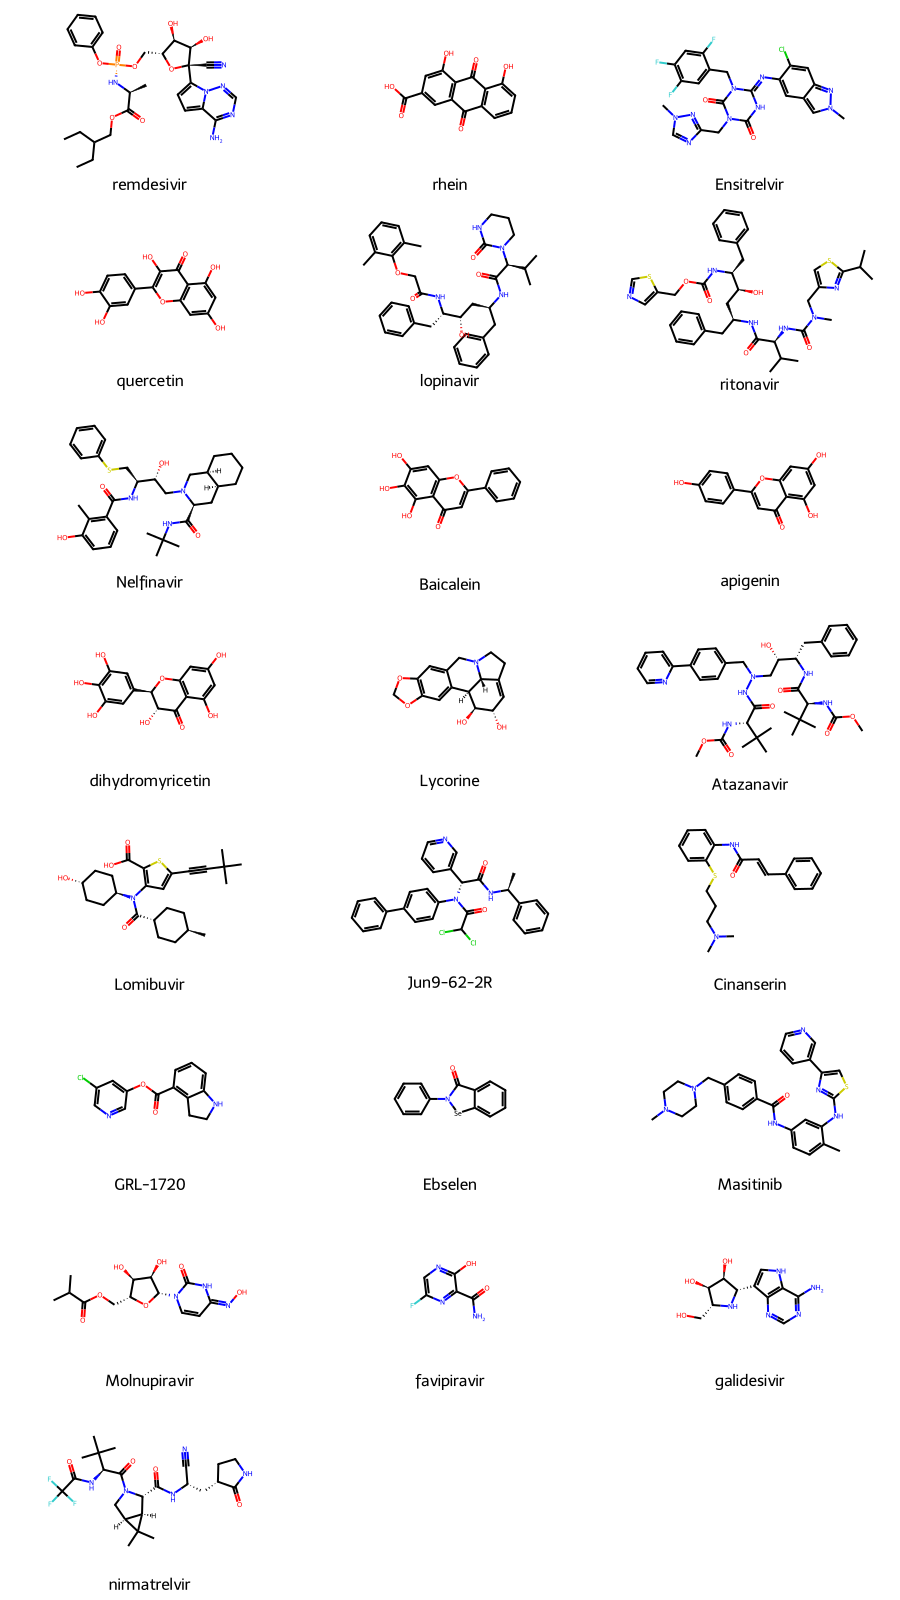

In [ ]:
# Extract SMILES and names
smiles = [x.split()[0] for x in new_smiles]
legends = [x.split()[1] for x in new_smiles]

ms = [Chem.MolFromSmiles(s) for s in smiles]
img = Draw.MolsToGridImage(ms, legends=legends, molsPerRow=3, subImgSize=(300, 200))
img

In [ ]:
models = {
    'CNN_Classifier': None,
    'RNN_Classifier': None,
}

X = Data.iloc[:, :-1]
Y = Data.iloc[:, -1]

results = []
saved_models = {}

for name, model in models.items():
    print(f"\n--- Training {name} ---")

    if name == 'CNN_Classifier':
        model = Sequential([
            Input(shape=(X_pca.shape[1], 1)),
            Conv1D(filters=64, kernel_size=3, activation='relu'),
            Conv1D(filters=32, kernel_size=3, activation='relu'),
            Flatten(),
            Dense(128, activation='relu'),
            Dense(1, activation='sigmoid')
        ])
        model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    elif name == 'RNN_Classifier':
        model = Sequential([
            Input(shape=(X_pca.shape[1], 1)),
            LSTM(64, return_sequences=True),
            LSTM(32),
            Dense(1, activation='sigmoid')
        ])
        model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    if model is None:
        continue

    accuracy_scores, precision_scores, recall_scores, auc_scores, f1_scores = [], [], [], [], []

    for fold, (train_index, test_index) in enumerate(kf.split(X_pca, Y)):
        X_train, X_test = X_pca[train_index], X_pca[test_index]
        Y_train, Y_test = Y.iloc[train_index], Y.iloc[test_index]

        if name in ['CNN_Classifier', 'RNN_Classifier']:
            X_train = np.expand_dims(X_train, axis=2)
            X_test = np.expand_dims(X_test, axis=2)
            early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
            model.fit(X_train, Y_train, epochs=100, batch_size=32, verbose=0,
                      validation_data=(X_test, Y_test), callbacks=[early_stopping])
            Y_pred_prob = model.predict(X_test).flatten()
        else:
            model.fit(X_train, Y_train)
            Y_pred_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else model.predict(X_test)

        Y_pred = (Y_pred_prob > 0.5).astype(int)

        accuracy_scores.append(accuracy_score(Y_test, Y_pred))
        precision_scores.append(precision_score(Y_test, Y_pred))
        recall_scores.append(recall_score(Y_test, Y_pred))
        auc_scores.append(roc_auc_score(Y_test, Y_pred_prob))
        f1_scores.append(f1_score(Y_test, Y_pred))

    saved_models[name] = model
    print('Successful!')

    # Calculate averages
    mean_accuracy = np.mean(accuracy_scores)
    mean_precision = np.mean(precision_scores)
    mean_recall = np.mean(recall_scores)
    mean_f1 = np.mean(f1_scores)
    mean_auc = np.mean(auc_scores)

    # Append to results for the table
    results.append({
        'Model': name,
        'Accuracy': mean_accuracy,
        'Precision': mean_precision,
        'Recall': mean_recall,
        'F1 Score': mean_f1,
        'AUC Score': mean_auc
    })

# Save models (for Keras models, use model.save() instead of joblib)
for name, model in saved_models.items():
    if 'Classifier' in name and ('CNN' in name or 'RNN' in name):
        model.save(f'{name}_model.h5')
    else:
        joblib.dump(model, f'{name}_model.pkl')

# Display results table
results_df = pd.DataFrame(results)
results_df = results_df.set_index('Model')  # Optional: set Model as index for table-like display
results_df